# TASK 4: Email Spam Detection with Machine Learning

## Project Description

This project uses Natural Language Processing (NLP) and Machine Learning to classify messages as Spam or Ham. TF-IDF is used for text feature extraction, and Multinomial Naive Bayes and Logistic Regression are trained to detect spam messages.

Importing Libraries

In [1]:
# Importing required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Libraries imported successfully!")

Libraries imported successfully!


## 3. Loading Dataset

The SMS Spam Collection dataset is loaded using pandas. It contains messages labeled as spam or ham.

In [3]:
# Loading the dataset

df = pd.read_csv(
    "SMSSpamCollection",
    sep="\t",
    header=None,
    names=["Label", "Message"]
)

df.head()

,Label,Message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


## 4. Data Overview

The dataset is examined to understand its structure, message labels, and class distribution.

In [4]:
# Checking dataset information

print("Dataset Shape:", df.shape)

print("\nClass Counts:")
print(df["Label"].value_counts())

print("\nClass Percentages:")
print(df["Label"].value_counts(normalize=True) * 100)

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (5572, 2)

Class Counts:
Label
ham     4825
spam     747
Name: count, dtype: int64

Class Percentages:
Label
ham     86.593683
spam    13.406317
Name: proportion, dtype: float64

Missing Values:
Label      0
Message    0
dtype: int64


## 5. Text Preprocessing

Text preprocessing is performed to clean messages by converting them to lowercase, removing punctuation, and eliminating stopwords.

In [5]:
# Text preprocessing

import nltk
from nltk.corpus import stopwords

nltk.download("stopwords")

stop_words = set(stopwords.words("english"))

def preprocess_text(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', '', text)
    words = text.split()
    words = [word for word in words if word not in stop_words]
    return " ".join(words)

df["Cleaned_Message"] = df["Message"].apply(preprocess_text)

df[["Message", "Cleaned_Message"]].head()

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


,Message,Cleaned_Message
0,"Go until jurong point, crazy.. Available only ...",go jurong point crazy available bugis n great ...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry wkly comp win fa cup final tkts st ...
3,U dun say so early hor... U c already then say...,u dun say early hor u c already say
4,"Nah I don't think he goes to usf, he lives aro...",nah dont think goes usf lives around though


## 6. Class Distribution Visualization

The distribution of spam and ham messages is visualized using a bar chart to understand the dataset balance.

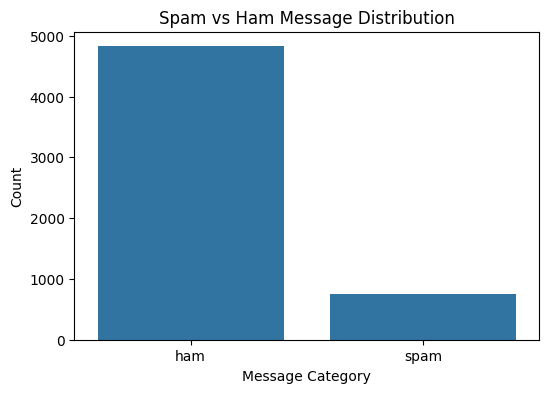

In [6]:
# Visualizing spam and ham distribution

plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="Label")

plt.title("Spam vs Ham Message Distribution")
plt.xlabel("Message Category")
plt.ylabel("Count")

plt.show()

## 7. TF-IDF Feature Extraction

TF-IDF (Term Frequency-Inverse Document Frequency) converts text messages into numerical features. It measures the importance of a word in a message relative to the entire dataset.

In [7]:
# Applying TF-IDF Vectorization

tfidf = TfidfVectorizer()

X = tfidf.fit_transform(df["Cleaned_Message"])
y = df["Label"].map({"ham": 0, "spam": 1})

print("TF-IDF Shape:", X.shape)
print("Features extracted successfully!")

TF-IDF Shape: (5572, 8480)
Features extracted successfully!


## 8. Train-Test Split

The dataset is divided into training and testing sets. The training set is used to train the models, while the testing set is used to evaluate their performance.

In [8]:
# Splitting the dataset

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (4457, 8480)
Testing data: (1115, 8480)


## 9. Multinomial Naive Bayes Classifier

Multinomial Naive Bayes is a commonly used Machine Learning algorithm for text classification. It is trained to identify spam and legitimate messages.

In [9]:
# Training Multinomial Naive Bayes

nb_model = MultinomialNB()

nb_model.fit(X_train, y_train)

y_pred_nb = nb_model.predict(X_test)

print("Naive Bayes model trained successfully!")

Naive Bayes model trained successfully!


## 10. Logistic Regression Classifier

Logistic Regression is a supervised Machine Learning algorithm used for binary classification. It is trained to classify messages as spam or ham.

In [10]:
# Training Logistic Regression

lr_model = LogisticRegression(max_iter=1000)

lr_model.fit(X_train, y_train)

y_pred_lr = lr_model.predict(X_test)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


## 11. Model Evaluation

Both classifiers are evaluated using Accuracy, Precision, Recall, and F1-score to compare their performance in spam detection.

In [11]:
# Evaluating both models

models = {
    "Multinomial Naive Bayes": y_pred_nb,
    "Logistic Regression": y_pred_lr
}

for name, predictions in models.items():
    print("\n", name)
    print("Accuracy:", accuracy_score(y_test, predictions))
    print("Precision:", precision_score(y_test, predictions))
    print("Recall:", recall_score(y_test, predictions))
    print("F1 Score:", f1_score(y_test, predictions))


 Multinomial Naive Bayes
Accuracy: 0.9632286995515695
Precision: 1.0
Recall: 0.7248322147651006
F1 Score: 0.8404669260700389

 Logistic Regression
Accuracy: 0.9587443946188341
Precision: 1.0
Recall: 0.6912751677852349
F1 Score: 0.8174603174603174


## 12. Confusion Matrix

A confusion matrix is used to visualize the classification results and identify correctly and incorrectly predicted spam and ham messages.

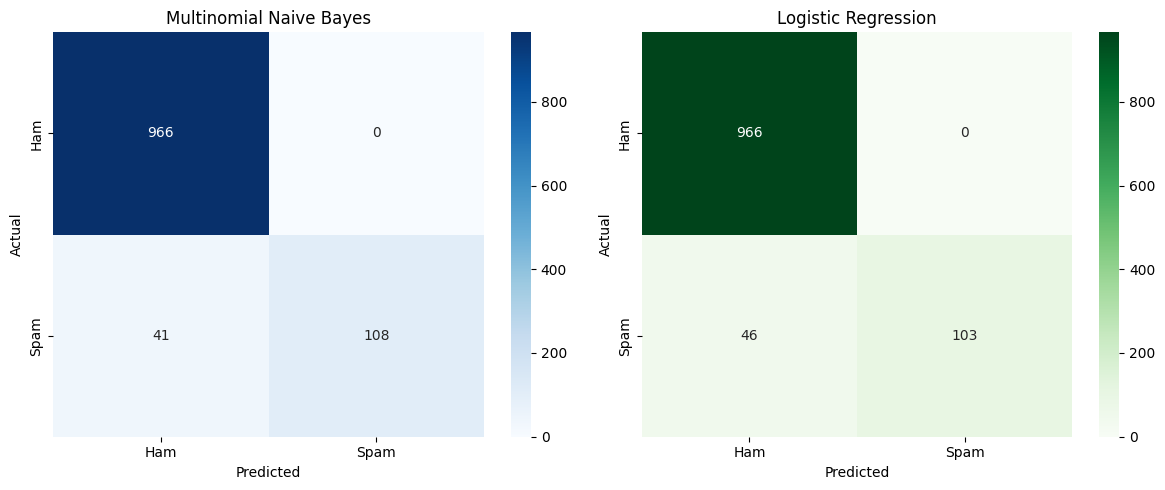

In [12]:
# Confusion Matrix for both classifiers

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_nb = confusion_matrix(y_test, y_pred_nb)

sns.heatmap(
    cm_nb,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"],
    ax=axes[0]
)

axes[0].set_title("Multinomial Naive Bayes")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

cm_lr = confusion_matrix(y_test, y_pred_lr)

sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"],
    ax=axes[1]
)

axes[1].set_title("Logistic Regression")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

## 13. Importance of Recall in Spam Detection

Recall is particularly important in spam detection because it measures how many actual spam messages are correctly identified by the model. High recall helps reduce the number of spam messages that are mistakenly classified as legitimate (ham), preventing unwanted or potentially harmful messages from reaching the user.

## 14. WordCloud Visualization

WordCloud visualizations are generated to display the most frequently occurring words in spam and ham messages. This helps identify common patterns in each category.

In [13]:
# Installing WordCloud library

!pip install wordcloud

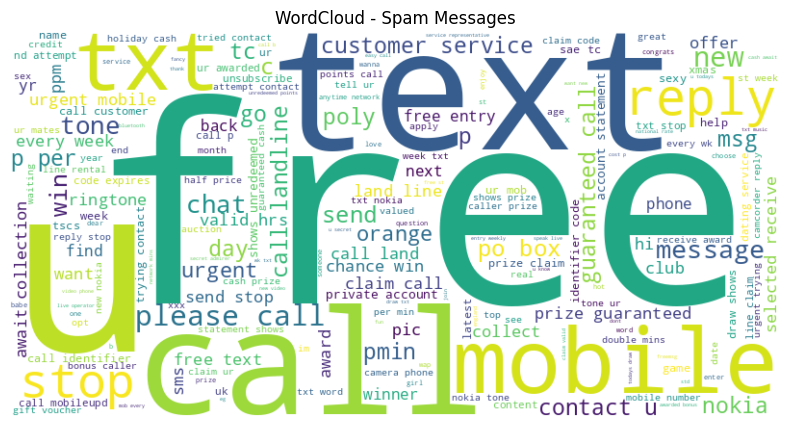

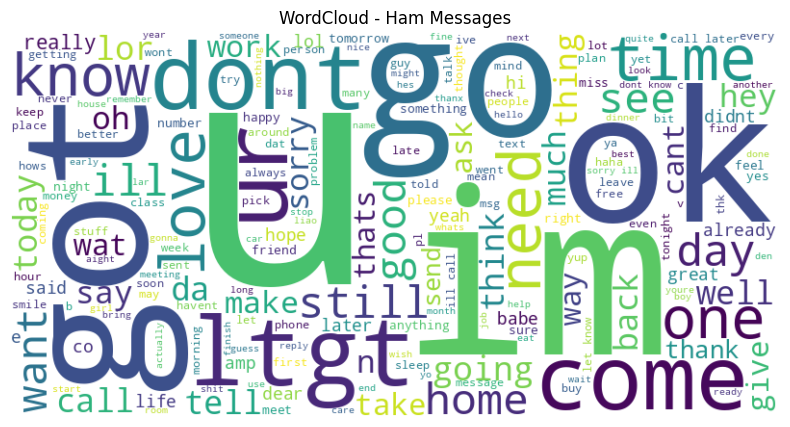

In [14]:
# WordCloud for Spam and Ham messages

from wordcloud import WordCloud

spam_text = " ".join(
    df[df["Label"] == "spam"]["Cleaned_Message"]
)

ham_text = " ".join(
    df[df["Label"] == "ham"]["Cleaned_Message"]
)

# Spam WordCloud
spam_wordcloud = WordCloud(
    width=800,
    height=400,
    background_color="white"
).generate(spam_text)

plt.figure(figsize=(10, 5))
plt.imshow(spam_wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("WordCloud - Spam Messages")
plt.show()

# Ham WordCloud
ham_wordcloud = WordCloud(
    width=800,
    height=400,
    background_color="white"
).generate(ham_text)

plt.figure(figsize=(10, 5))
plt.imshow(ham_wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("WordCloud - Ham Messages")
plt.show()

## 15. Conclusion

In this project, an Email Spam Detection system was developed using Natural Language Processing and Machine Learning. The SMS Spam Collection dataset was preprocessed, and TF-IDF was used for feature extraction. Multinomial Naive Bayes and Logistic Regression classifiers were trained and evaluated using Accuracy, Precision, Recall, F1-score, and Confusion Matrix. WordCloud visualizations were also generated to identify common words in spam and ham messages. This project demonstrates how Machine Learning can be used to classify spam and legitimate messages effectively.